# A disclosed, engineered representation advantage
This experiment asks whether a circuit-derived representation helps on a
task explicitly constructed from that representation. It does **not** test
quantum computational advantage. All features are simulated classically.

A fixed six-qubit circuit produces local X/Y/Z measurements. A fixed linear
teacher defines labels. Task, seeds, training sizes, search grids and the
primary comparison were frozen before evaluating fresh data. Pilot data are
separate. The protocol freeze is local, not an externally registered study.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/qkb").is_dir())
sys.path.insert(0, str(ROOT / "scripts"))
from report_engineered import validate
spec, execution, scores = validate()
print("Frozen:", spec['frozen_at_utc'])
print("Evaluation began:", execution['started_at_utc'])
print("Protocol SHA256:", execution['protocol_sha256'])
print("Source hashes, sample separation and every saved prediction score verified.")

Matplotlib is building the font cache; this may take a moment.


Frozen: 2026-10-24T06:44:24.053907+00:00
Evaluation began: 2026-10-24T06:44:25.549668+00:00
Protocol SHA256: dff2262ca0b6f6ef26e47d7abb8c13e5a9d21c99f9ed2ce2e0dcc7d603b062a6
Source hashes, sample separation and every saved prediction score verified.


## The circuit representation
Local X/Y/Z expectations on each of six qubits give 18 features. The teacher
labels a fixed weighted sum of these features. The RBF projected kernel then
measures distances between examples in this feature space.

In [2]:
sys.path.insert(0, str(ROOT / "src"))
from qkb.engineered import make_circuit
print(make_circuit().draw(output="text", fold=100))

      ┌────────────────────────────────┐  ┌─────────────────────────────┐            »
q_0: ─┤ Ry(1.737408265716691 + 2*x[0]) ├──┤ Rz(2.66547525846012 + x[1]) ├────■───────»
     ┌┴────────────────────────────────┴┐┌┴─────────────────────────────┴┐ ┌─┴─┐     »
q_1: ┤ Ry(-1.7570551736719822 + 2*x[1]) ├┤ Rz(0.3484057879560731 + x[2]) ├─┤ X ├──■──»
     ├──────────────────────────────────┤├───────────────────────────────┤ └───┘┌─┴─┐»
q_2: ┤ Ry(-2.5722079043654826 + 2*x[2]) ├┤ Rz(-3.127155960721114 + x[3]) ├──────┤ X ├»
     └┬────────────────────────────────┬┘├───────────────────────────────┤      └───┘»
q_3: ─┤ Ry(2.850398630254691 + 2*x[3]) ├─┤ Rz(2.2908240814635557 + x[4]) ├───────────»
     ┌┴────────────────────────────────┤ ├───────────────────────────────┤           »
q_4: ┤ Ry(2.7444173740883264 + 2*x[4]) ├─┤ Rz(1.2431367913572282 + x[5]) ├───────────»
     ├─────────────────────────────────┤ ├───────────────────────────────┴┐          »
q_5: ┤ Ry(2.6726939602157547 + 2*x[5]) ├─┤ 

## Primary comparison, fixed before evaluation
n=128 versus a classical baseline selected by **training-only** inner CV.
Intervals reflect ten independently generated datasets for one fixed teacher.
Other sizes and individual comparisons are secondary and unadjusted.

,n_train,model,runs,mean_acc,sd_acc,ci95_low,ci95_high
22,128,Classical same-feature logistic,10,0.9328,0.0211,0.9177,0.9479
21,128,Classical same-feature RBF,10,0.9100,0.0248,0.8922,0.9277
27,128,Projected quantum kernel,10,0.9100,0.0248,0.8922,0.9277
24,128,Gradient boosting,10,0.5090,0.0254,0.4908,0.5271
23,128,Fourier+pairwise SVM,10,0.5027,0.0215,0.4873,0.5181
26,128,Nonentangling projection RBF,10,0.5018,0.0261,0.4831,0.5205
25,128,MLP,10,0.4932,0.0300,0.4717,0.5146
20,128,Classical raw-input selection,10,0.4902,0.0283,0.4700,0.5104
28,128,RBF SVM,10,0.4896,0.0237,0.4727,0.5066
29,128,Random forest,10,0.4885,0.0233,0.4718,0.5052


,n_train,comparator,runs,mean_delta,sd_delta,ci95_low,ci95_high,wins,ties,losses
18,128,Classical raw-input selection,10,0.4197,0.033,0.3961,0.4434,10,0,0


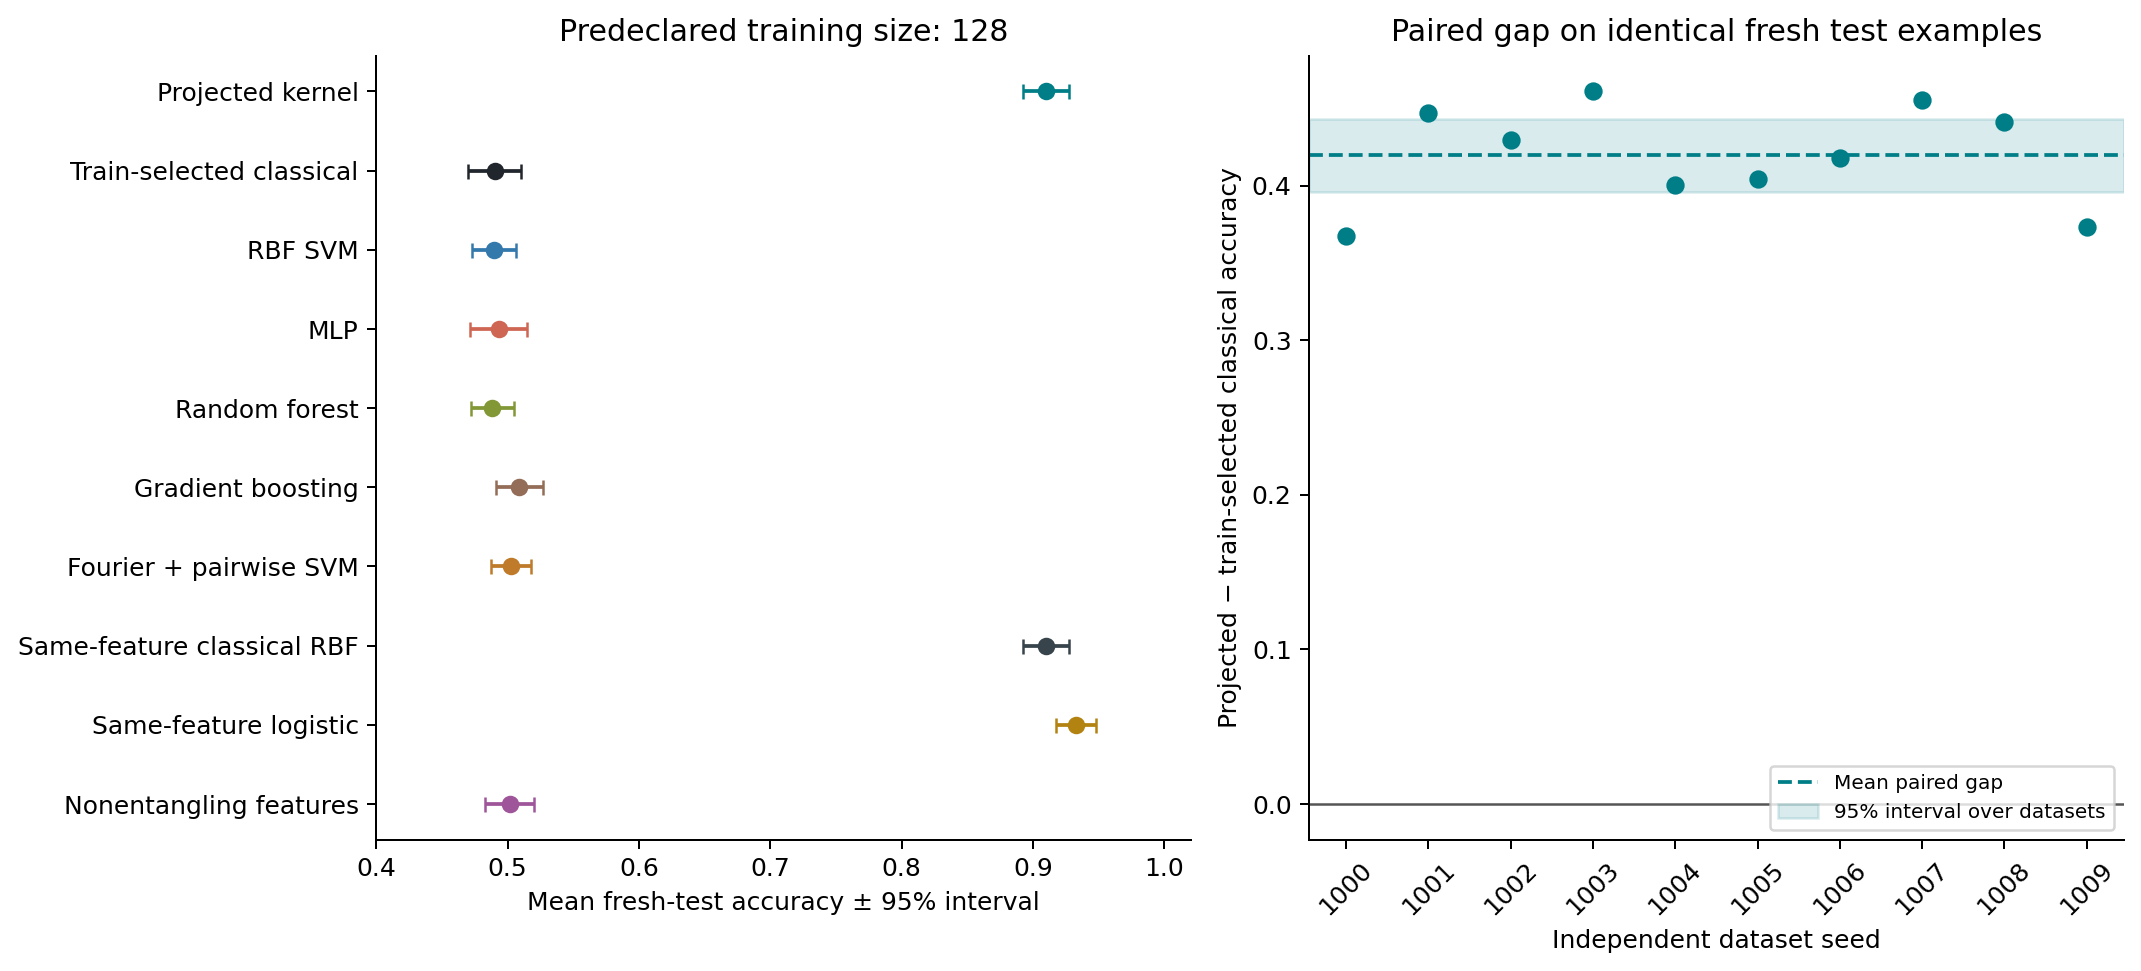

In [3]:
summary = pd.read_csv(ROOT / 'results/engineered/summary.csv')
paired = pd.read_csv(ROOT / 'results/engineered/paired_comparisons.csv')
n = spec['primary_comparison']['n_train']
display(summary[summary.n_train == n].sort_values('mean_acc', ascending=False).round(4))
display(paired[(paired.n_train == n) & (paired.comparator == 'Classical raw-input selection')].round(4))
display(Image(filename=str(ROOT / 'figures/engineered_primary_comparison.png')))

## Learning curves and the revealing controls
The direct classical RBF model given the same local-Pauli features must match
the precomputed projected kernel; this is checked on **every prediction**.
Logistic regression given these features can directly learn the linear teacher.
The nonentangling ablation removes CNOTs but retains the input encoding.
The raw-input Fourier competitor includes frequencies 1–4 and pairwise products.

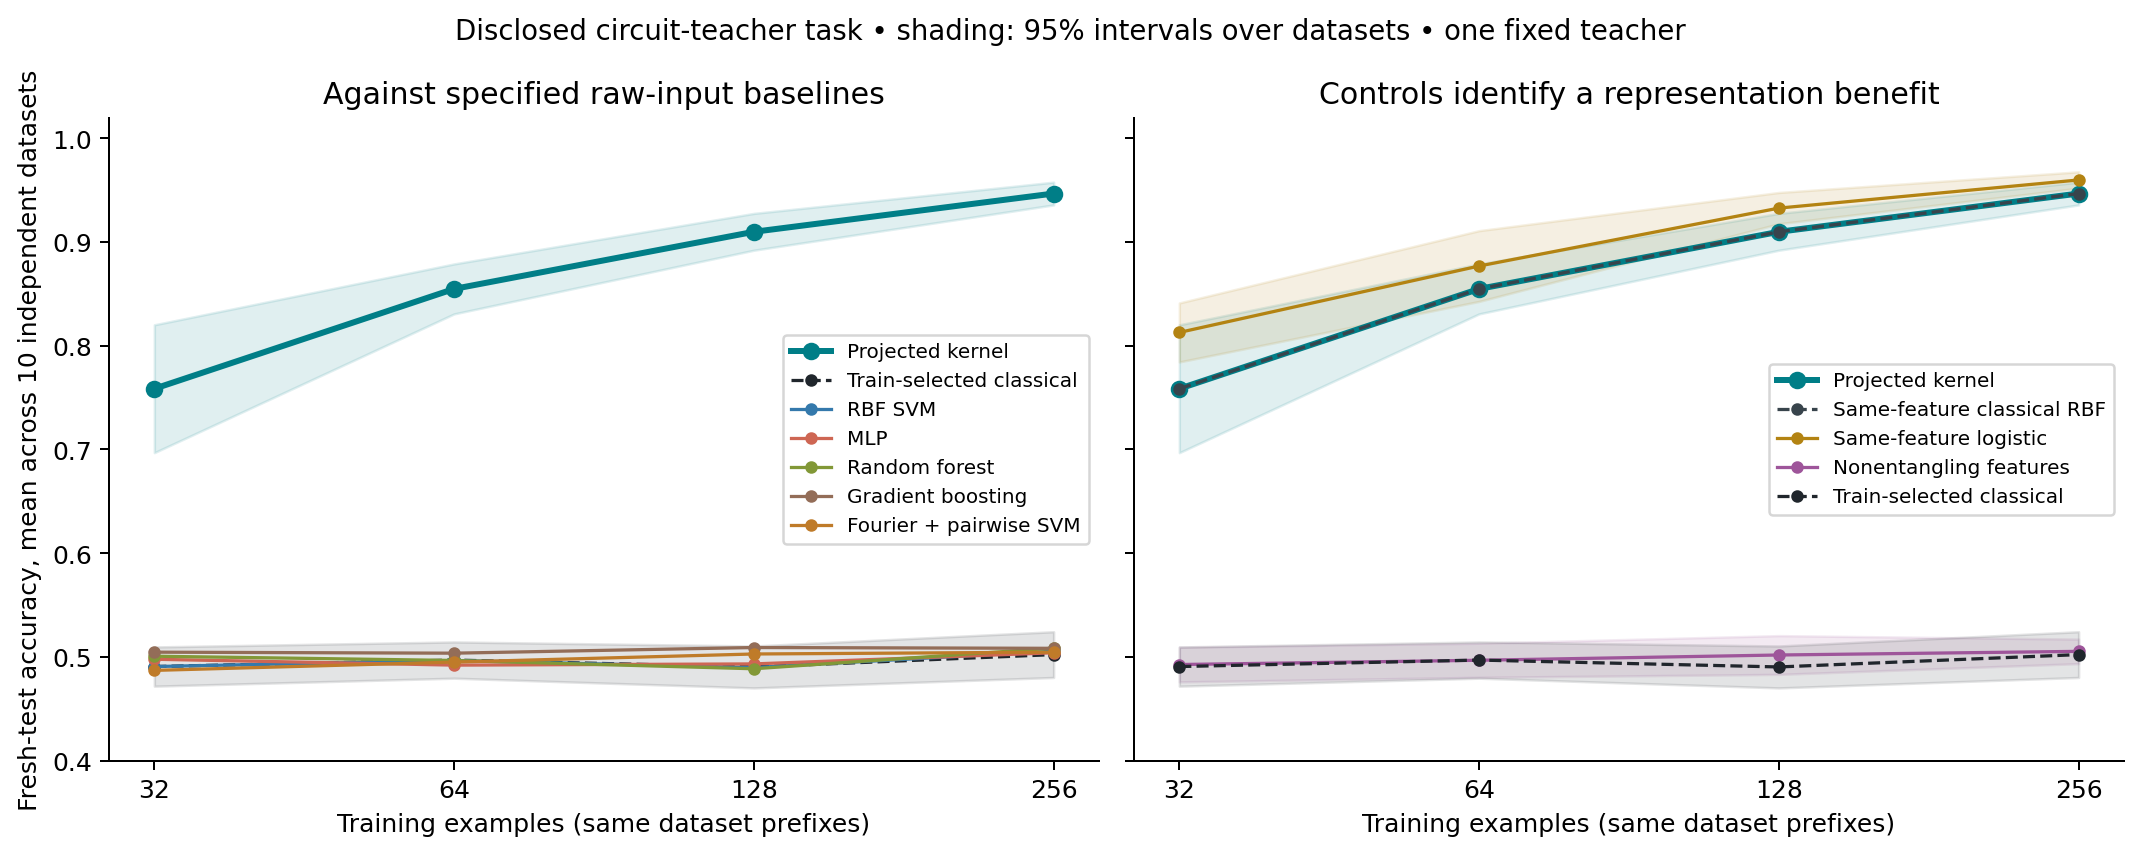

Same-feature RBF matches in all 40 dataset/training-size cases.


In [4]:
display(Image(filename=str(ROOT / 'figures/engineered_learning_curves.png')))
pivot = scores.pivot(index=['seed', 'n_train'], columns='model', values='test_acc')
assert np.array_equal(pivot['Projected quantum kernel'], pivot['Classical same-feature RBF'])
print("Same-feature RBF matches in all", len(pivot), "dataset/training-size cases.")

## Limits and reproducibility
This demonstrates the usefulness of an intentionally matched representation
against specified baselines. These six-qubit features are classically computed
here, so the result establishes no speedup or classical hardness. It is one
teacher and one input distribution, not evidence about ordinary datasets.
Hyperparameter searches have finite budgets; recorded warnings remain visible.

In [5]:
warnings = scores.groupby('model').fit_warning_count.sum().astype(int)
display(warnings.rename('recorded_tuning_warnings').to_frame())
display(Markdown("See [full methods and limitations](../ENGINEERED_RESULTS.md), the frozen protocol, and saved predictions."))

,recorded_tuning_warnings
model,
Classical raw-input selection,6
Classical same-feature RBF,0
Classical same-feature logistic,0
Fourier+pairwise SVM,0
Gradient boosting,1
MLP,62
Nonentangling projection RBF,0
Projected quantum kernel,0
RBF SVM,0


See [full methods and limitations](../ENGINEERED_RESULTS.md), the frozen protocol, and saved predictions.

To reproduce the unchanged study from the repo root:
```bash
python scripts/run_engineered.py --stage evaluate --overwrite
python scripts/report_engineered.py
python scripts/build_notebooks.py --execute
```
Editing scientific sources invalidates their frozen hashes. A different task
should be a separately versioned experiment, preserving this result.